# JavaScript Transpiling and Polyfills for Extended Support

This course covers how to use transpiling and polyfilling to ensure modern JavaScript code runs across all browsers. It explores Babel for ES6-to-ES5 transpilation, core-js for polyfilling missing built-ins, and TypeScript as a compile-to-JS superset language.

## Table of Contents

- [Module 01: Implementing Backward Compatibility Using Transpiling](#module-01)
- [Module 02: Adding Missing Functionality Using Polyfills](#module-02)
- [Module 03: TypeScript Transpiling](#module-03)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

try:
    _NB_DIR = Path(__vsc_ipynb_file__).parent
except NameError:
    try:
        import ipynbname
        _NB_DIR = ipynbname.path().parent
    except Exception:
        _NB_DIR = Path.cwd()

def render_diagram(image_path, width=900):
    p = Path(image_path)
    if not p.is_absolute():
        p = _NB_DIR / p
    data = base64.b64encode(p.read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))


<a id="module-01"></a>
## Module 01: Implementing Backward Compatibility Using Transpiling

_Covers JavaScript version history, what transpiling means, and how to use Babel to convert modern ES6+ code into ES5 for broad browser support._

### JavaScript Version History

JavaScript is standardised as ECMAScript (ES). Versions are released by the TC39 committee and assigned both a number and a year name starting from ES2015.

**Key versions:**

| Version | Name | Year | Notable additions |
|---|---|---|---|
| ES1 | ECMAScript 1 | 1997 | Initial standard |
| ES2 | ECMAScript 2 | 1998 | Editorial changes |
| ES3 | ECMAScript 3 | 1999 | Regex, try/catch, strict equality |
| ES4 | ECMAScript 4 | — | Abandoned |
| ES5 | ECMAScript 5 | 2009 | `use strict`, JSON, array methods, getters/setters |
| ES6 | ECMAScript 2015 | 2015 | Arrow functions, classes, destructuring, `let`/`const`, Promises |
| ES-Year | ECMAScript 2016–2021+ | Annual | Yearly incremental releases |


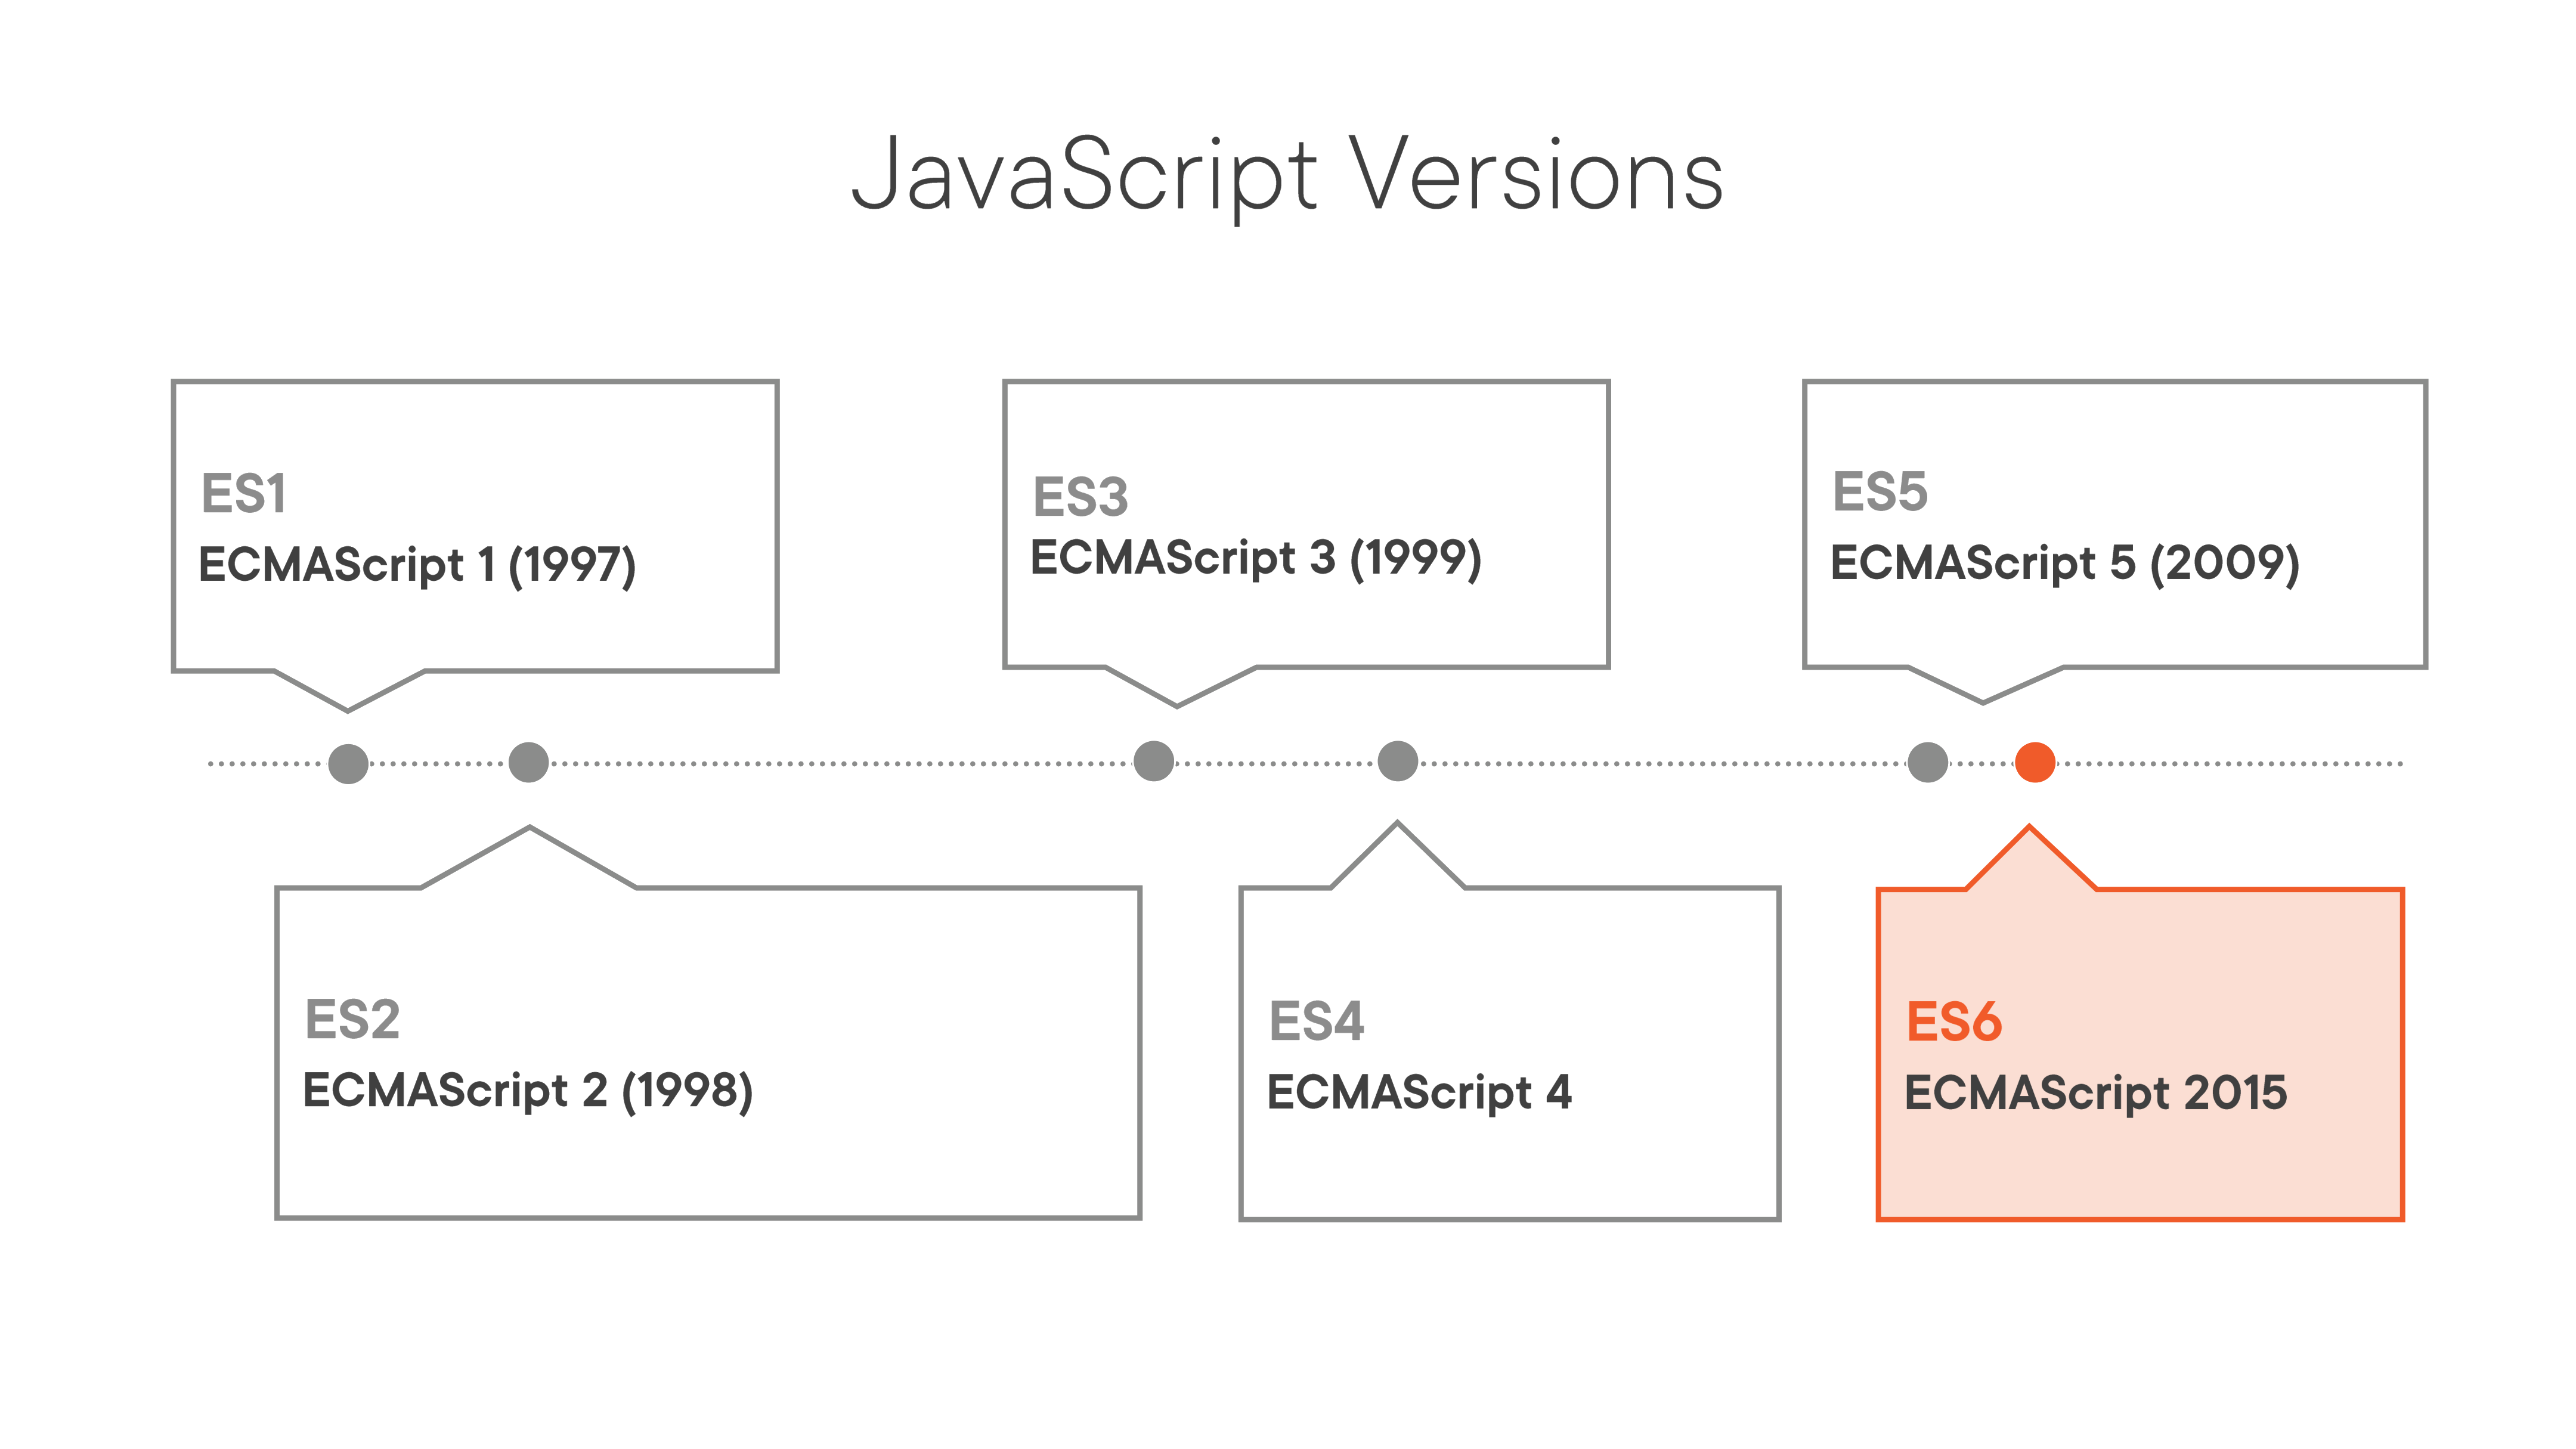

In [2]:
render_diagram(Path("assets/01-ecmascript-versions-timeline.png"))

### ES5 Language Features

ES5 (2009) introduced the features that became the baseline for browser-compatible code.

#### Strict Equality

The `===` operator checks both type and value, unlike `==` which coerces types:

```javascript
function isTypeAndValueEqual(numberVal, stringVal) {
  return numberVal === stringVal;
}
console.log(isTypeAndValueEqual(2, '2')); // false
console.log(isTypeAndValueEqual(2, 2));   // true
```

#### Switch Statements

```javascript
function dayName(day) {
  switch (day) {
    case 1: return 'Monday';
    case 2: return 'Tuesday';
    // ...
    case 7: return 'Sunday';
  }
}
console.log(dayName(2)); // Tuesday
```

#### Try/Catch Error Handling

```javascript
function tryAndGetValue() {
  try {
    // run code here
  } catch (err) {
    // execute if something goes wrong
  }
}
```

#### `use strict`

Activates strict mode — undeclared variables throw a `ReferenceError` instead of silently creating globals:

```javascript
"use strict"
x = 5; // ReferenceError: x is not defined
```

#### Array Methods

ES5 added functional iteration methods to arrays:

```javascript
var mylist = [1, 2, 3, 4, 5];
mylist.forEach(function(item) { });
mylist.map(function(item) { return item + 1; });
mylist.indexOf(4);
mylist.reduce(function(curr, next) { return curr + next; }, 0);
mylist.some(function(item) { return item > 10; });
mylist.every(function(item) { return item > 10; });
```

#### JSON

Native JSON serialisation/deserialisation:

```javascript
var mylist = [1, 2, 3, 4, 5];
console.log(JSON.stringify(mylist));       // '[1,2,3,4,5]'
var listFromJson = JSON.parse('[1,2,3,4,5]');
```

#### Getters and Setters

Object properties with computed get/set behaviour:

```javascript
var character = {
  first_name: "John",
  last_name: "Doe",
  get fullName() {
    return `${this.first_name} ${this.last_name}`;
  },
  set fullName(str) {
    [this.first_name, this.last_name] = str.split(" ");
  }
};
console.log(character.fullName); // John Doe
```

### ES6 Key Features

ES6 (ECMAScript 2015) introduced significant syntax improvements:

- **Arrow Functions** — concise function syntax with lexical `this`
- **Classes** — syntactic sugar over prototype-based inheritance
- **Object Destructuring** — extract values from objects/arrays into variables
- **`let` & `const`** — block-scoped variable declarations
- **Promises** — native async handling

### What is Transpiling?

> **Compiler:** Converts high-level human-readable code into lower-level machine code.

> **Transpiler:** Transforms the code of a language into another form of the _same_ language. Also referred to as source-to-source compilers. This process converts one higher-level language to another higher-level language.

Transpiling is needed because not all browsers support the latest JavaScript features. By transpiling ES6+ to ES5, code can run in older environments.


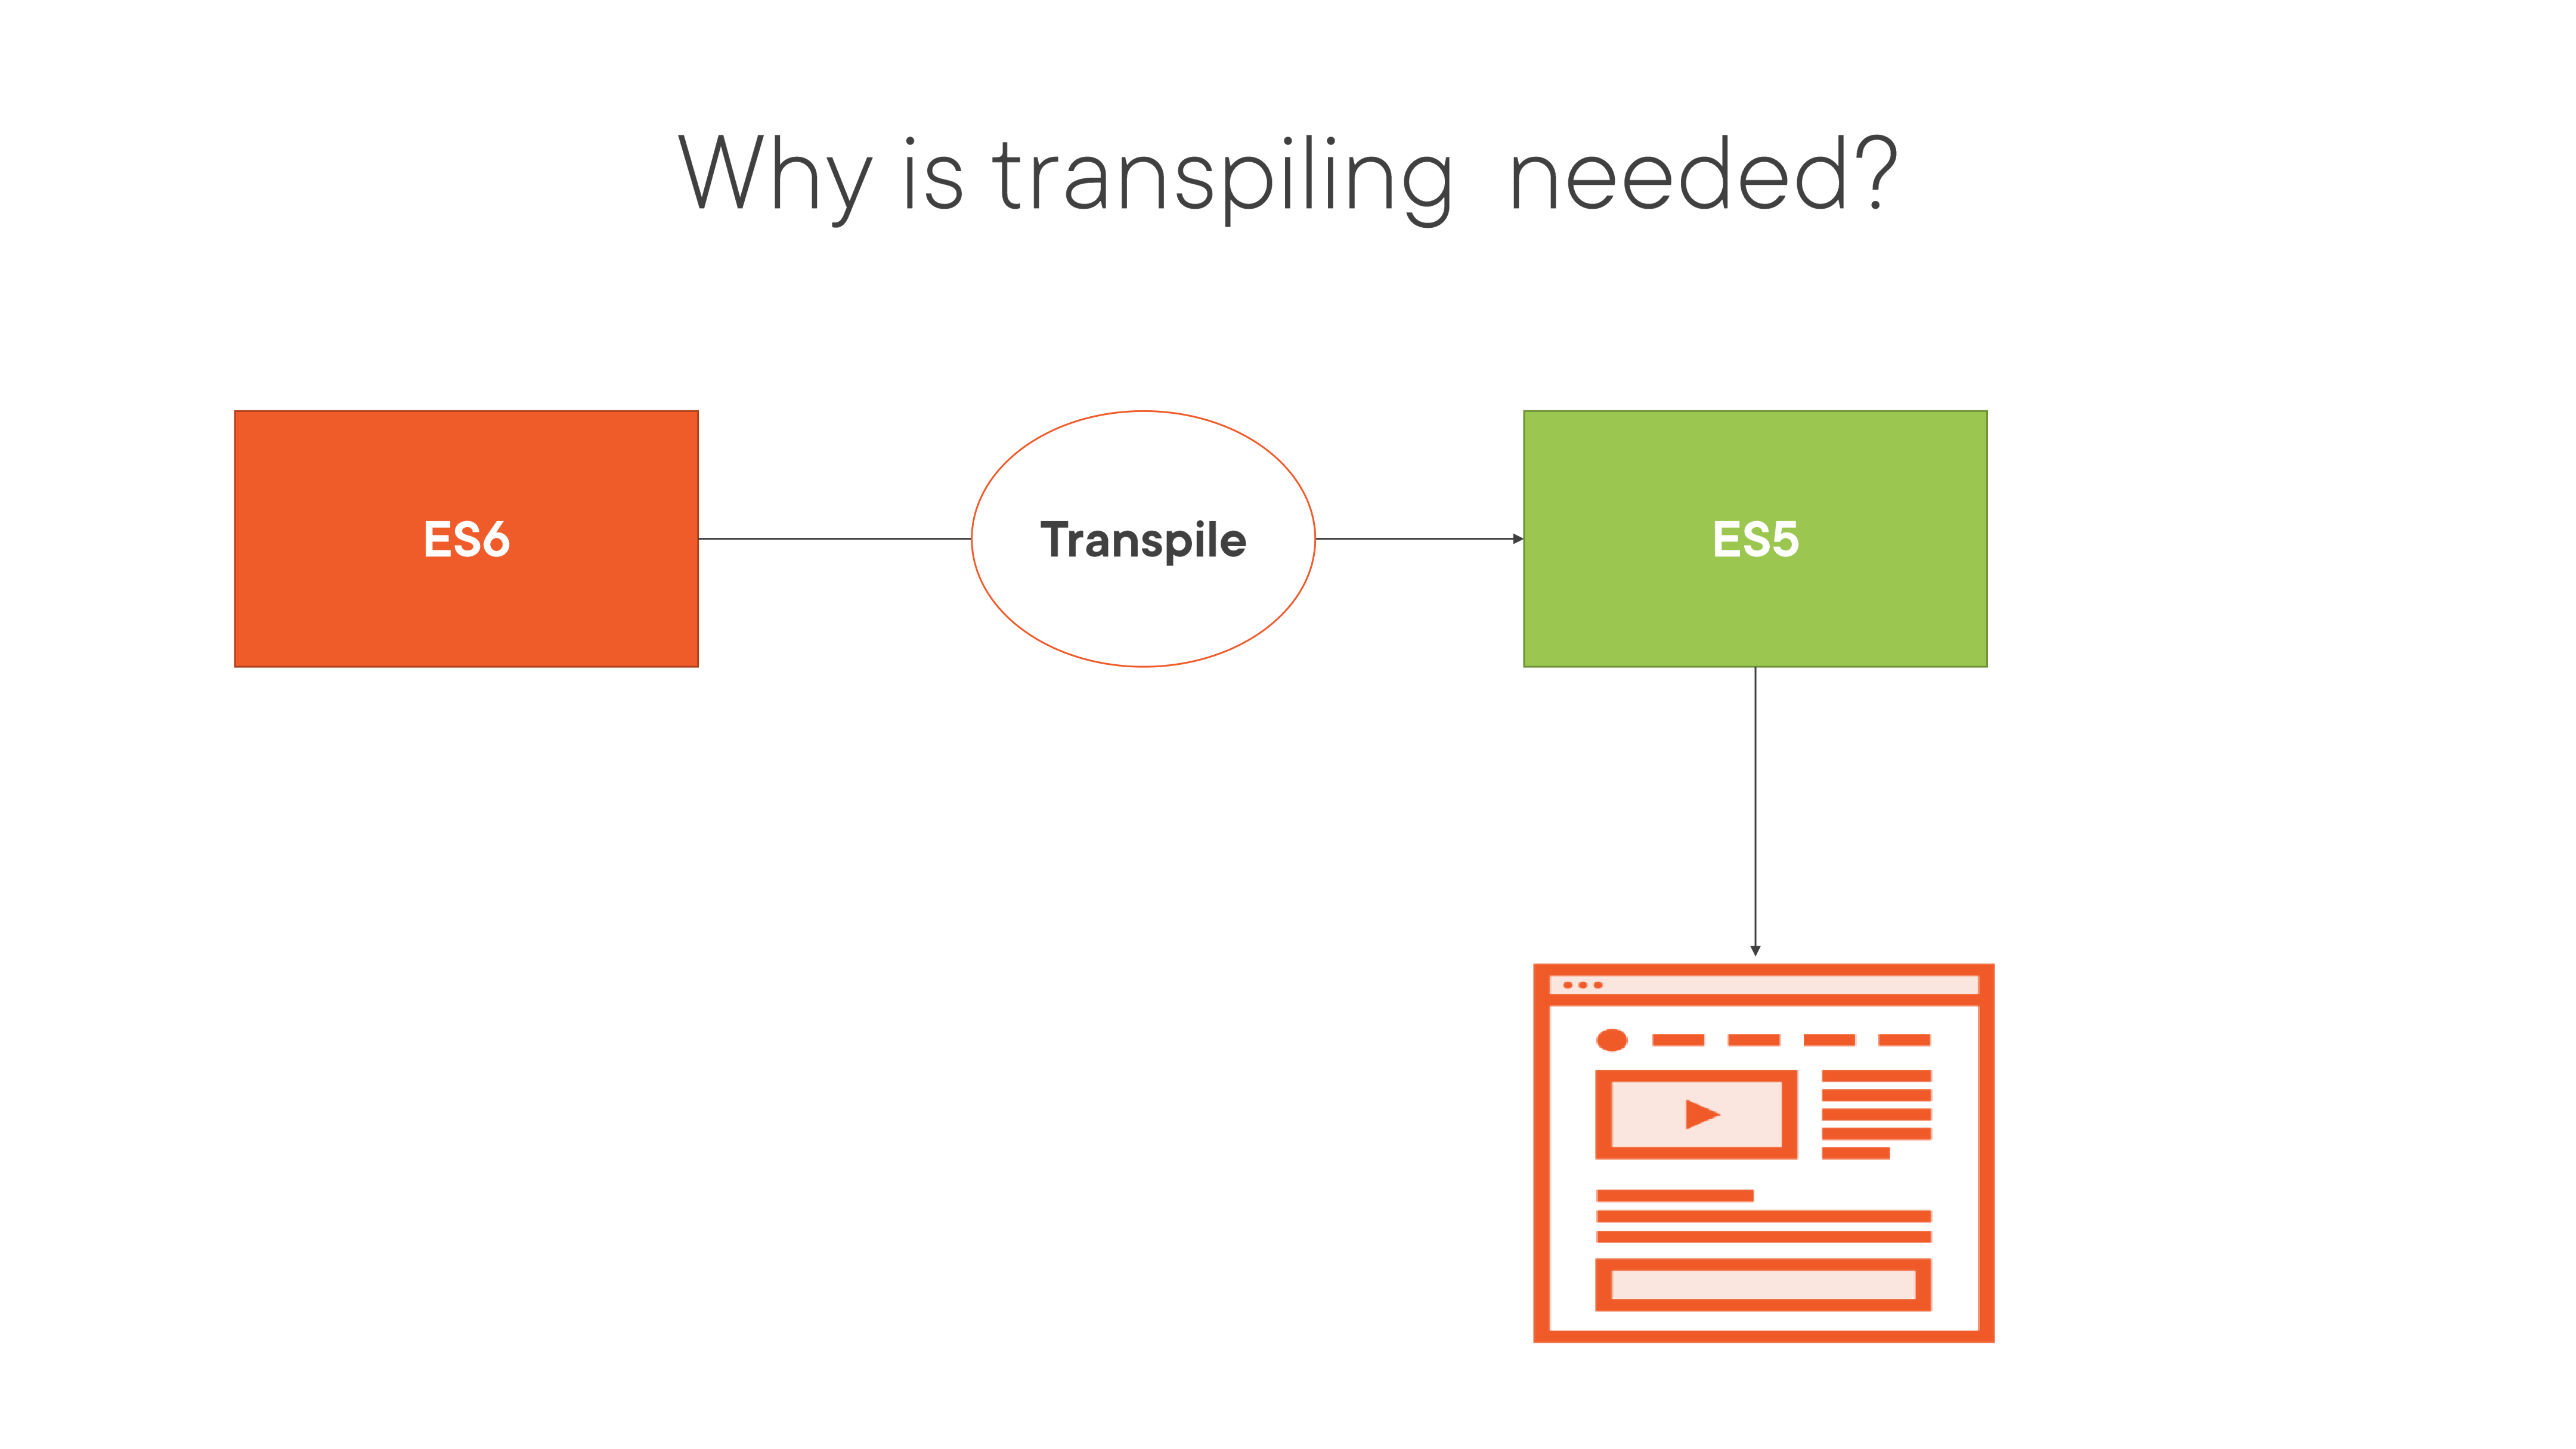

In [3]:
render_diagram(Path("assets/02-transpiling-flow.png"))

### Transpiling in Action: ES6 Default Parameters → ES5

A concrete example — the ES6 default parameter syntax is rewritten by the transpiler into an ES5-compatible `arguments` check:

**ES6 (source):**
```javascript
function printUserName(name = 'User') {
  console.log("Hello " + name);
}
```

**ES5 (transpiled output):**
```javascript
function printUserName() {
  var name = arguments.length > 0 && arguments[0] !== undefined
    ? arguments[0]
    : "User";
  console.log("Hello " + name);
}
```


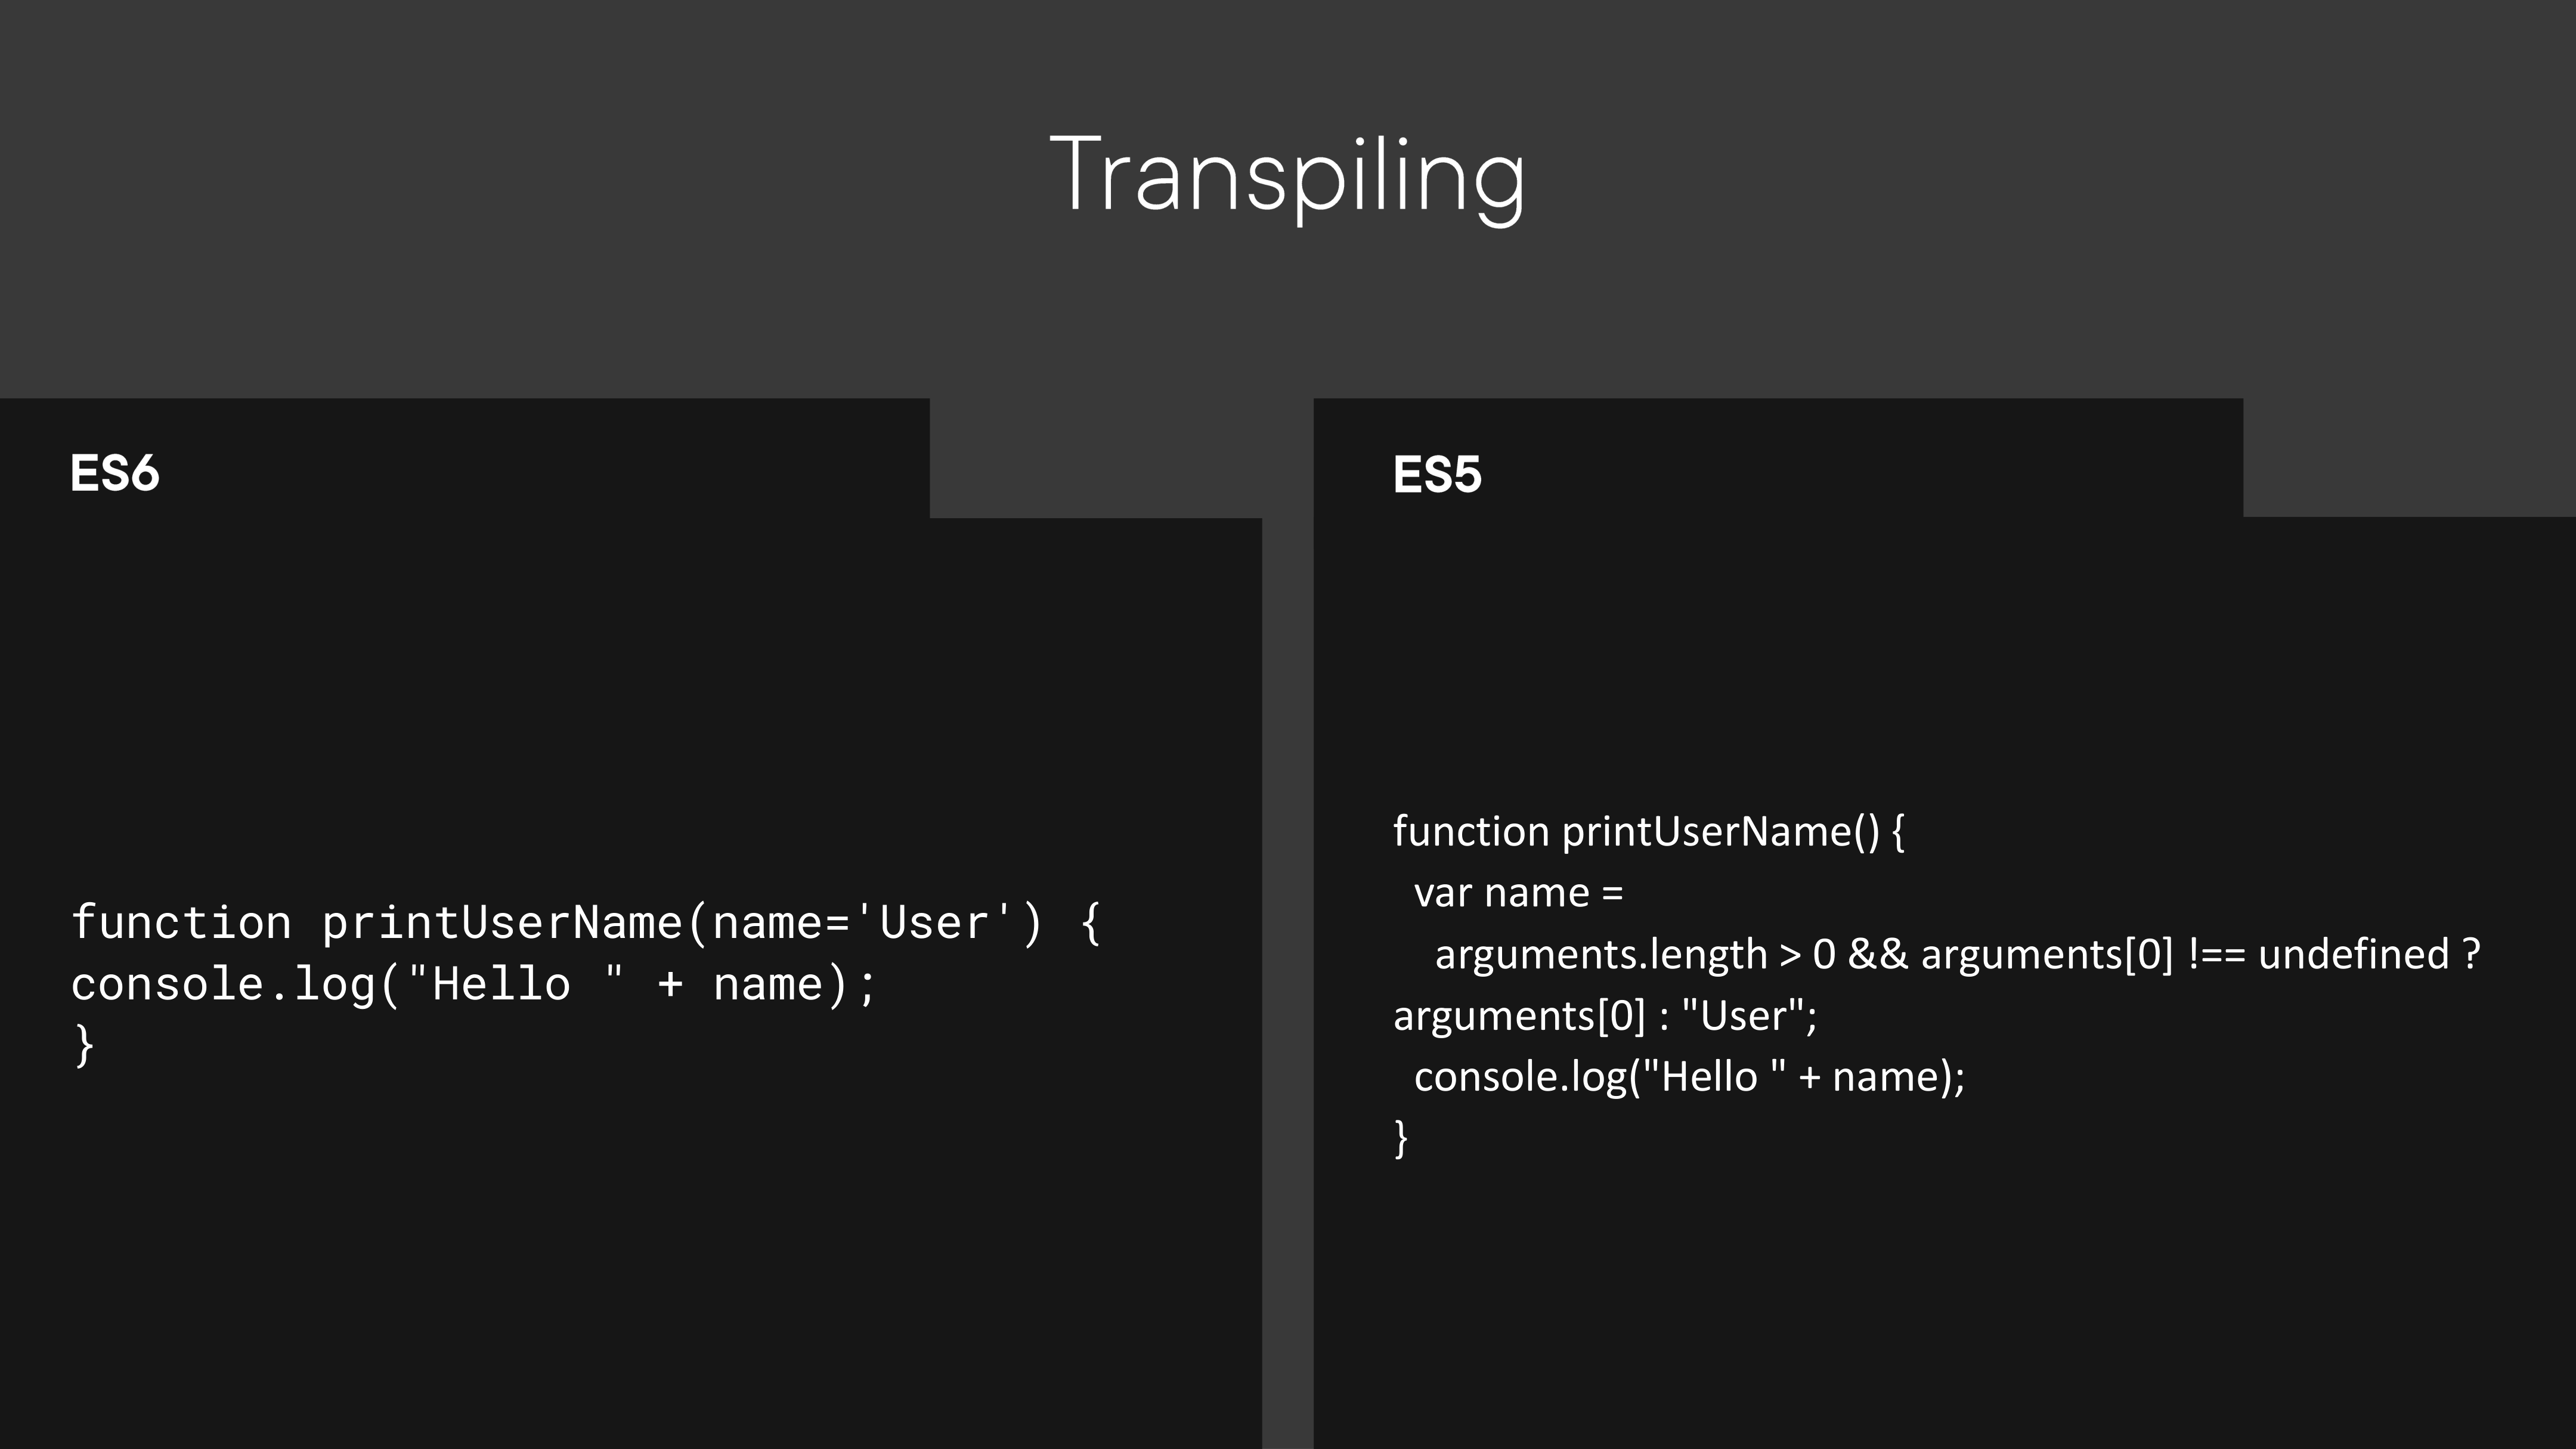

In [4]:
render_diagram(Path("assets/03-transpiling-code-comparison.png"))

### Do We Still Need Transpiling Today?

Modern browsers have good support for recent JavaScript versions, but transpiling remains relevant because:

- **Advanced features** — cutting-edge language features not yet supported by all browsers still need transpiling.
- **Legacy browser support** — enterprise, government, and accessibility requirements often mandate older browser support.
- **Optional chaining, nullish coalescing, etc.** — newer syntax like `user?.name` may not be available in all target environments.

### Introducing Babel

Babel is the standard JavaScript transpiler. It reads ES6+ source code and outputs equivalent ES5.

**Key components:**
- `@babel/core` — the core transpilation engine
- `@babel/cli` — command-line interface for running Babel
- `@babel/preset-env` — smart preset that automatically determines which transforms to apply based on target environments

### Configuring Babel

Babel is configured via a `babel.config.json` file:

```json
{
  "presets": ["@babel/preset-env"]
}
```

Install the required packages:

```bash
npm install --save-dev @babel/core @babel/cli @babel/preset-env
```

Add a build script to `package.json`:

```json
{
  "scripts": {
    "build": "babel src -d lib"
  }
}
```

This transpiles all files from the `src/` directory into `lib/`.

### Demo: Babel Transpiling

Three progressively-built Babel demos showing optional chaining, basic transpilation, and module transpilation.

See [`01-babel-transpiling-demos/`](01-babel-transpiling-demos/) for the full project.

**Demo 02_04** — optional chaining (`?.`) transpiled with `@babel/preset-env`:

```javascript
// src/main.js (ES6+ source)
let username = null;
let user = null;
const userName = user?.name;
```

**Demo 02_05** — function with default parameters:

```javascript
// src/main.js (ES6+ source)
// (uses same config — demonstrates preset-env handling defaults)
```

**Demo 02_06** — ES module imports/exports transpiled to CommonJS:

```javascript
// src/utils.js
export const add = (a, b) => a + b;
export const subtract = (a, b) => a - b;

// src/main.js
import { add, subtract } from './utils';
console.log(add(1, 2));      // 3
console.log(subtract(5, 3)); // 2
```

Run any demo:
```bash
cd 01-babel-transpiling-demos/02_04
npm install
npm run build   # outputs transpiled files to lib/
```

<a id="module-02"></a>
## Module 02: Adding Missing Functionality Using Polyfills

_Covers what polyfilling is, why it differs from transpiling, the core-js library, and the different ways to install polyfills in a web application._

### What is Polyfilling?

Transpiling handles **syntax** differences — it rewrites new syntax into equivalent old syntax. But transpiling cannot fix missing **built-in functions** that a browser simply doesn't implement.

For example, transpiling an ES6 `class` with `.includes()` rewrites the class structure but does not add `Array.prototype.includes` to a browser that lacks it.

**Polyfilling** solves this by adding the missing implementation directly to the browser's runtime environment: "add this feature to the browser if it doesn't already exist."


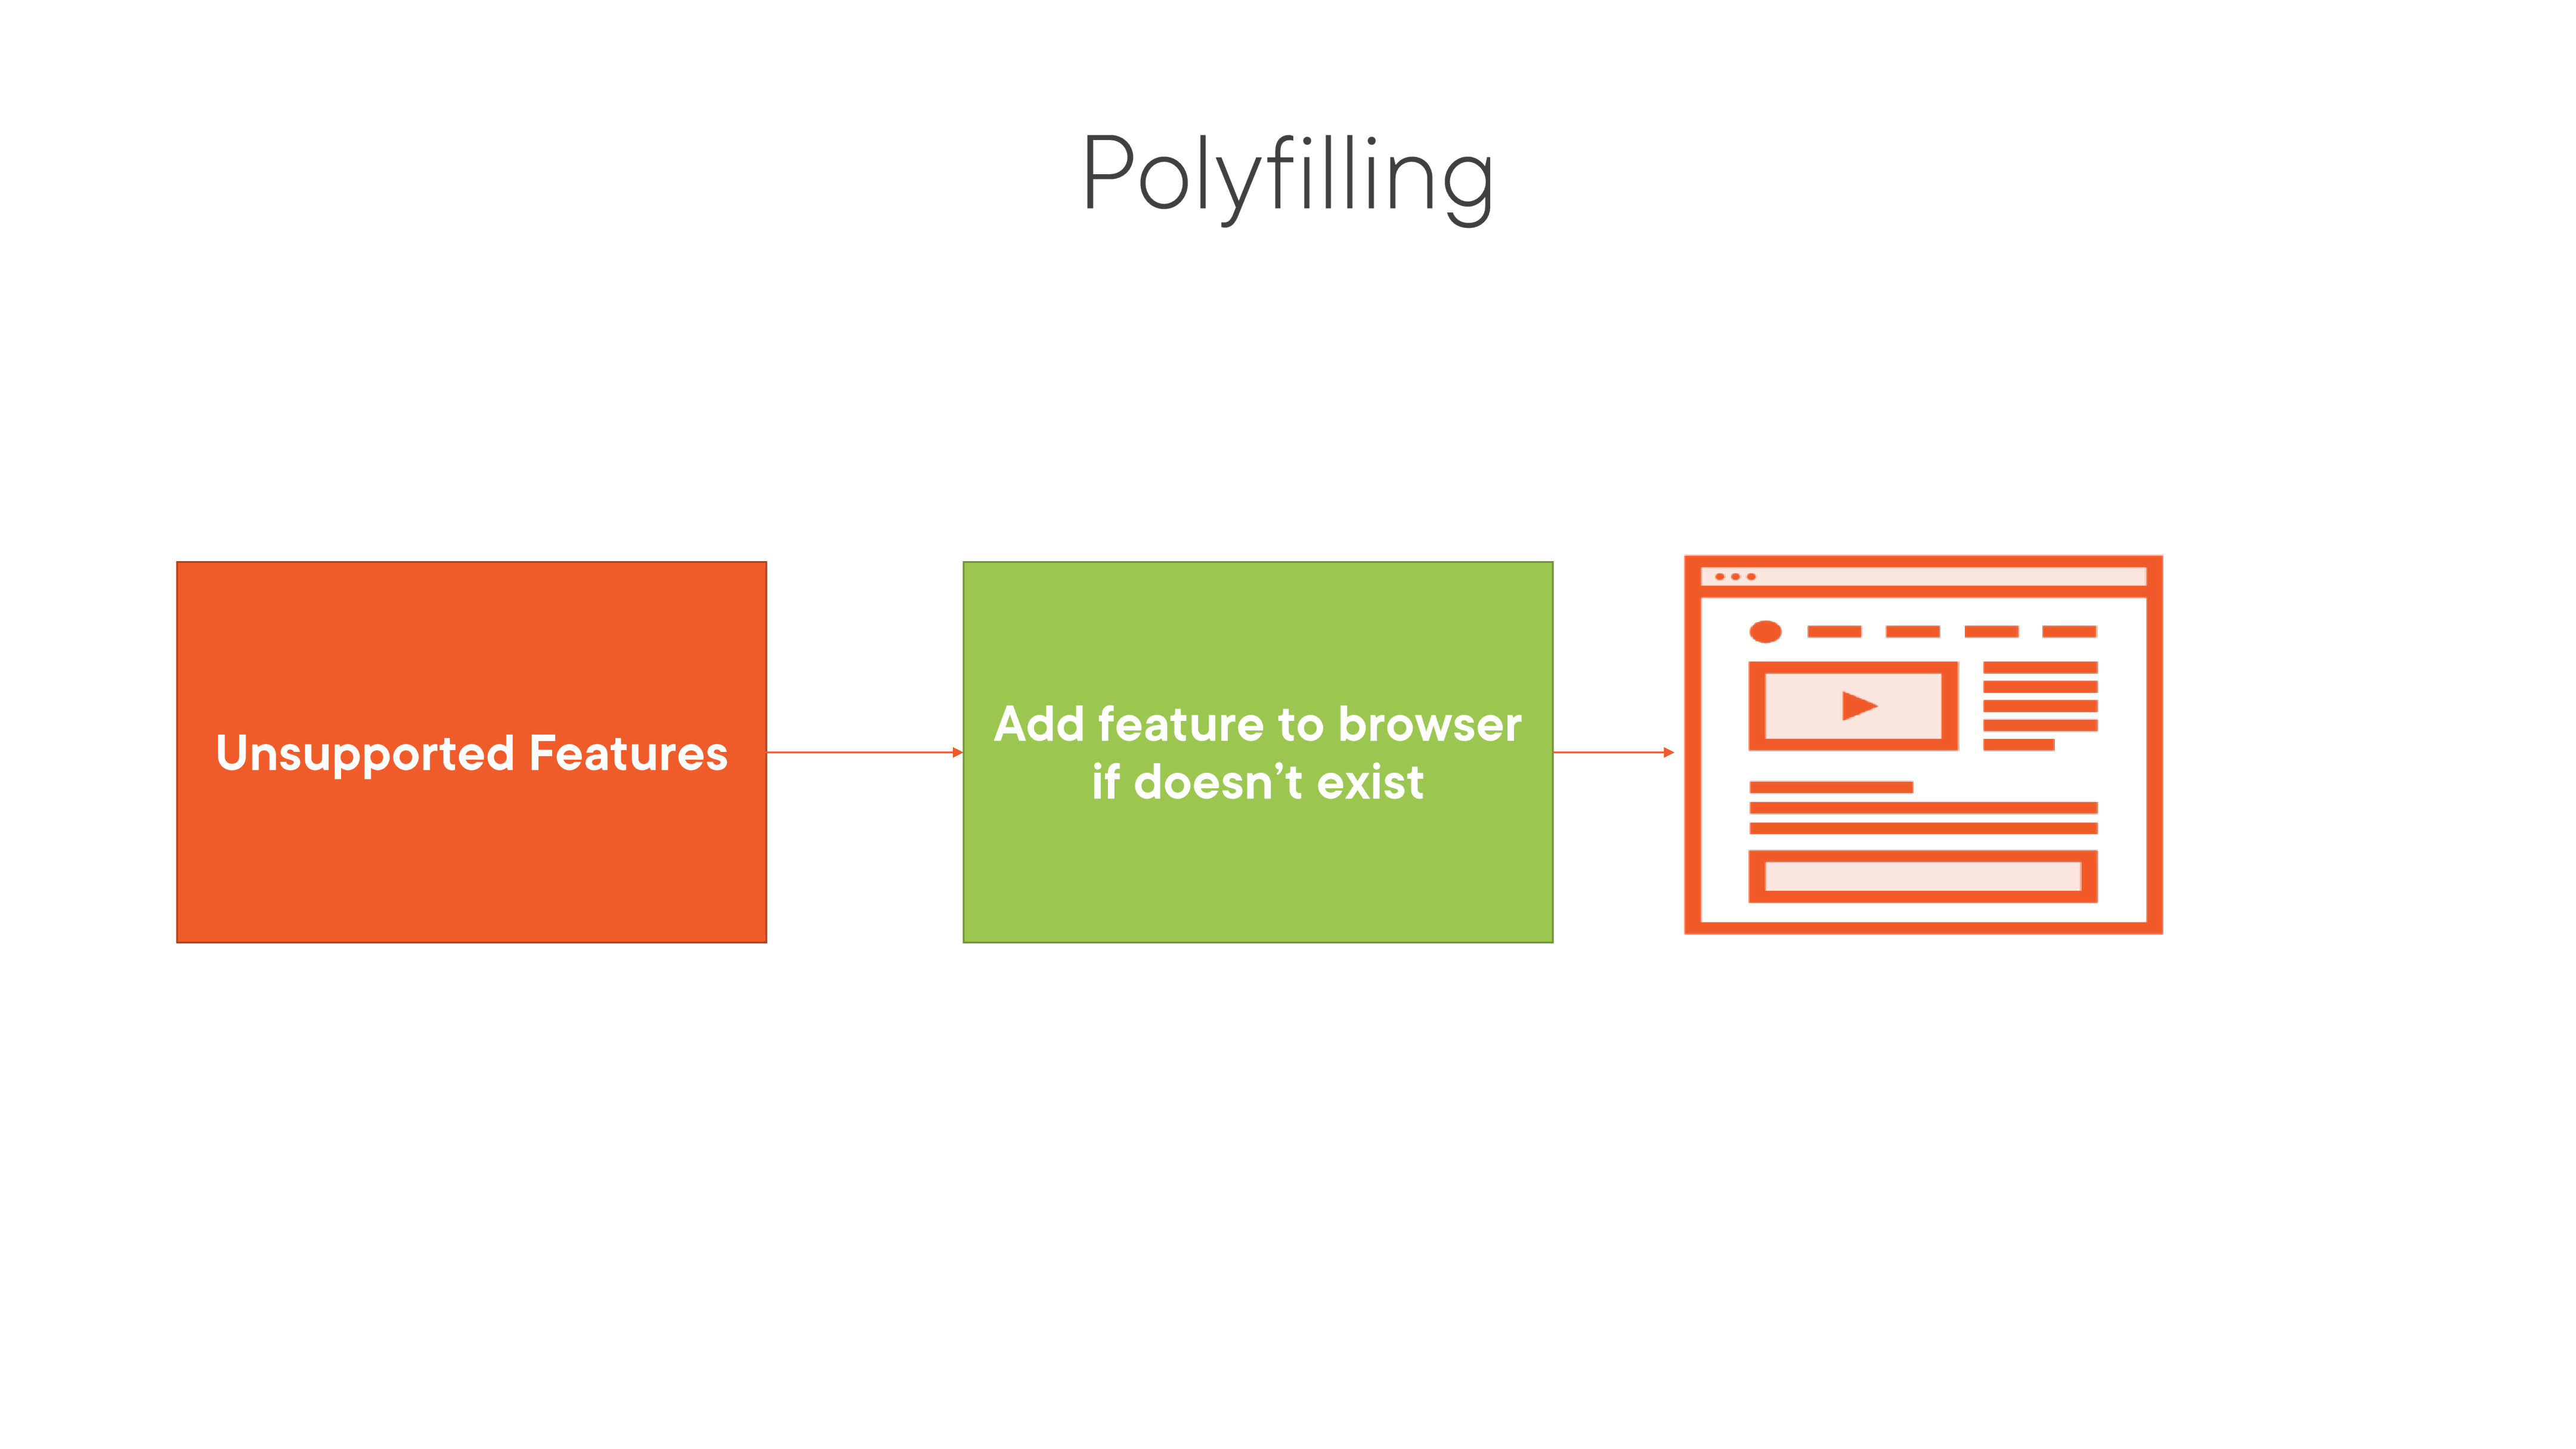

In [5]:
render_diagram(Path("assets/05-polyfilling-flow.png"))

### Why Polyfilling is Needed

- Browsers implement features at **different times** — the same built-in may be available in Chrome but not in an older version of Safari or IE.
- Polyfills ensure all required built-ins are available **before** the application runs.
- They also provide **backward-compatibility for deprecated features** on newer browsers when running older apps.

### The Transpiling + Polyfilling Gap

Transpiling rewrites class syntax into ES5-compatible constructor functions, but `.includes()` is still called on the resulting array. If the browser doesn't have `Array.prototype.includes`, the transpiled code still fails at runtime.


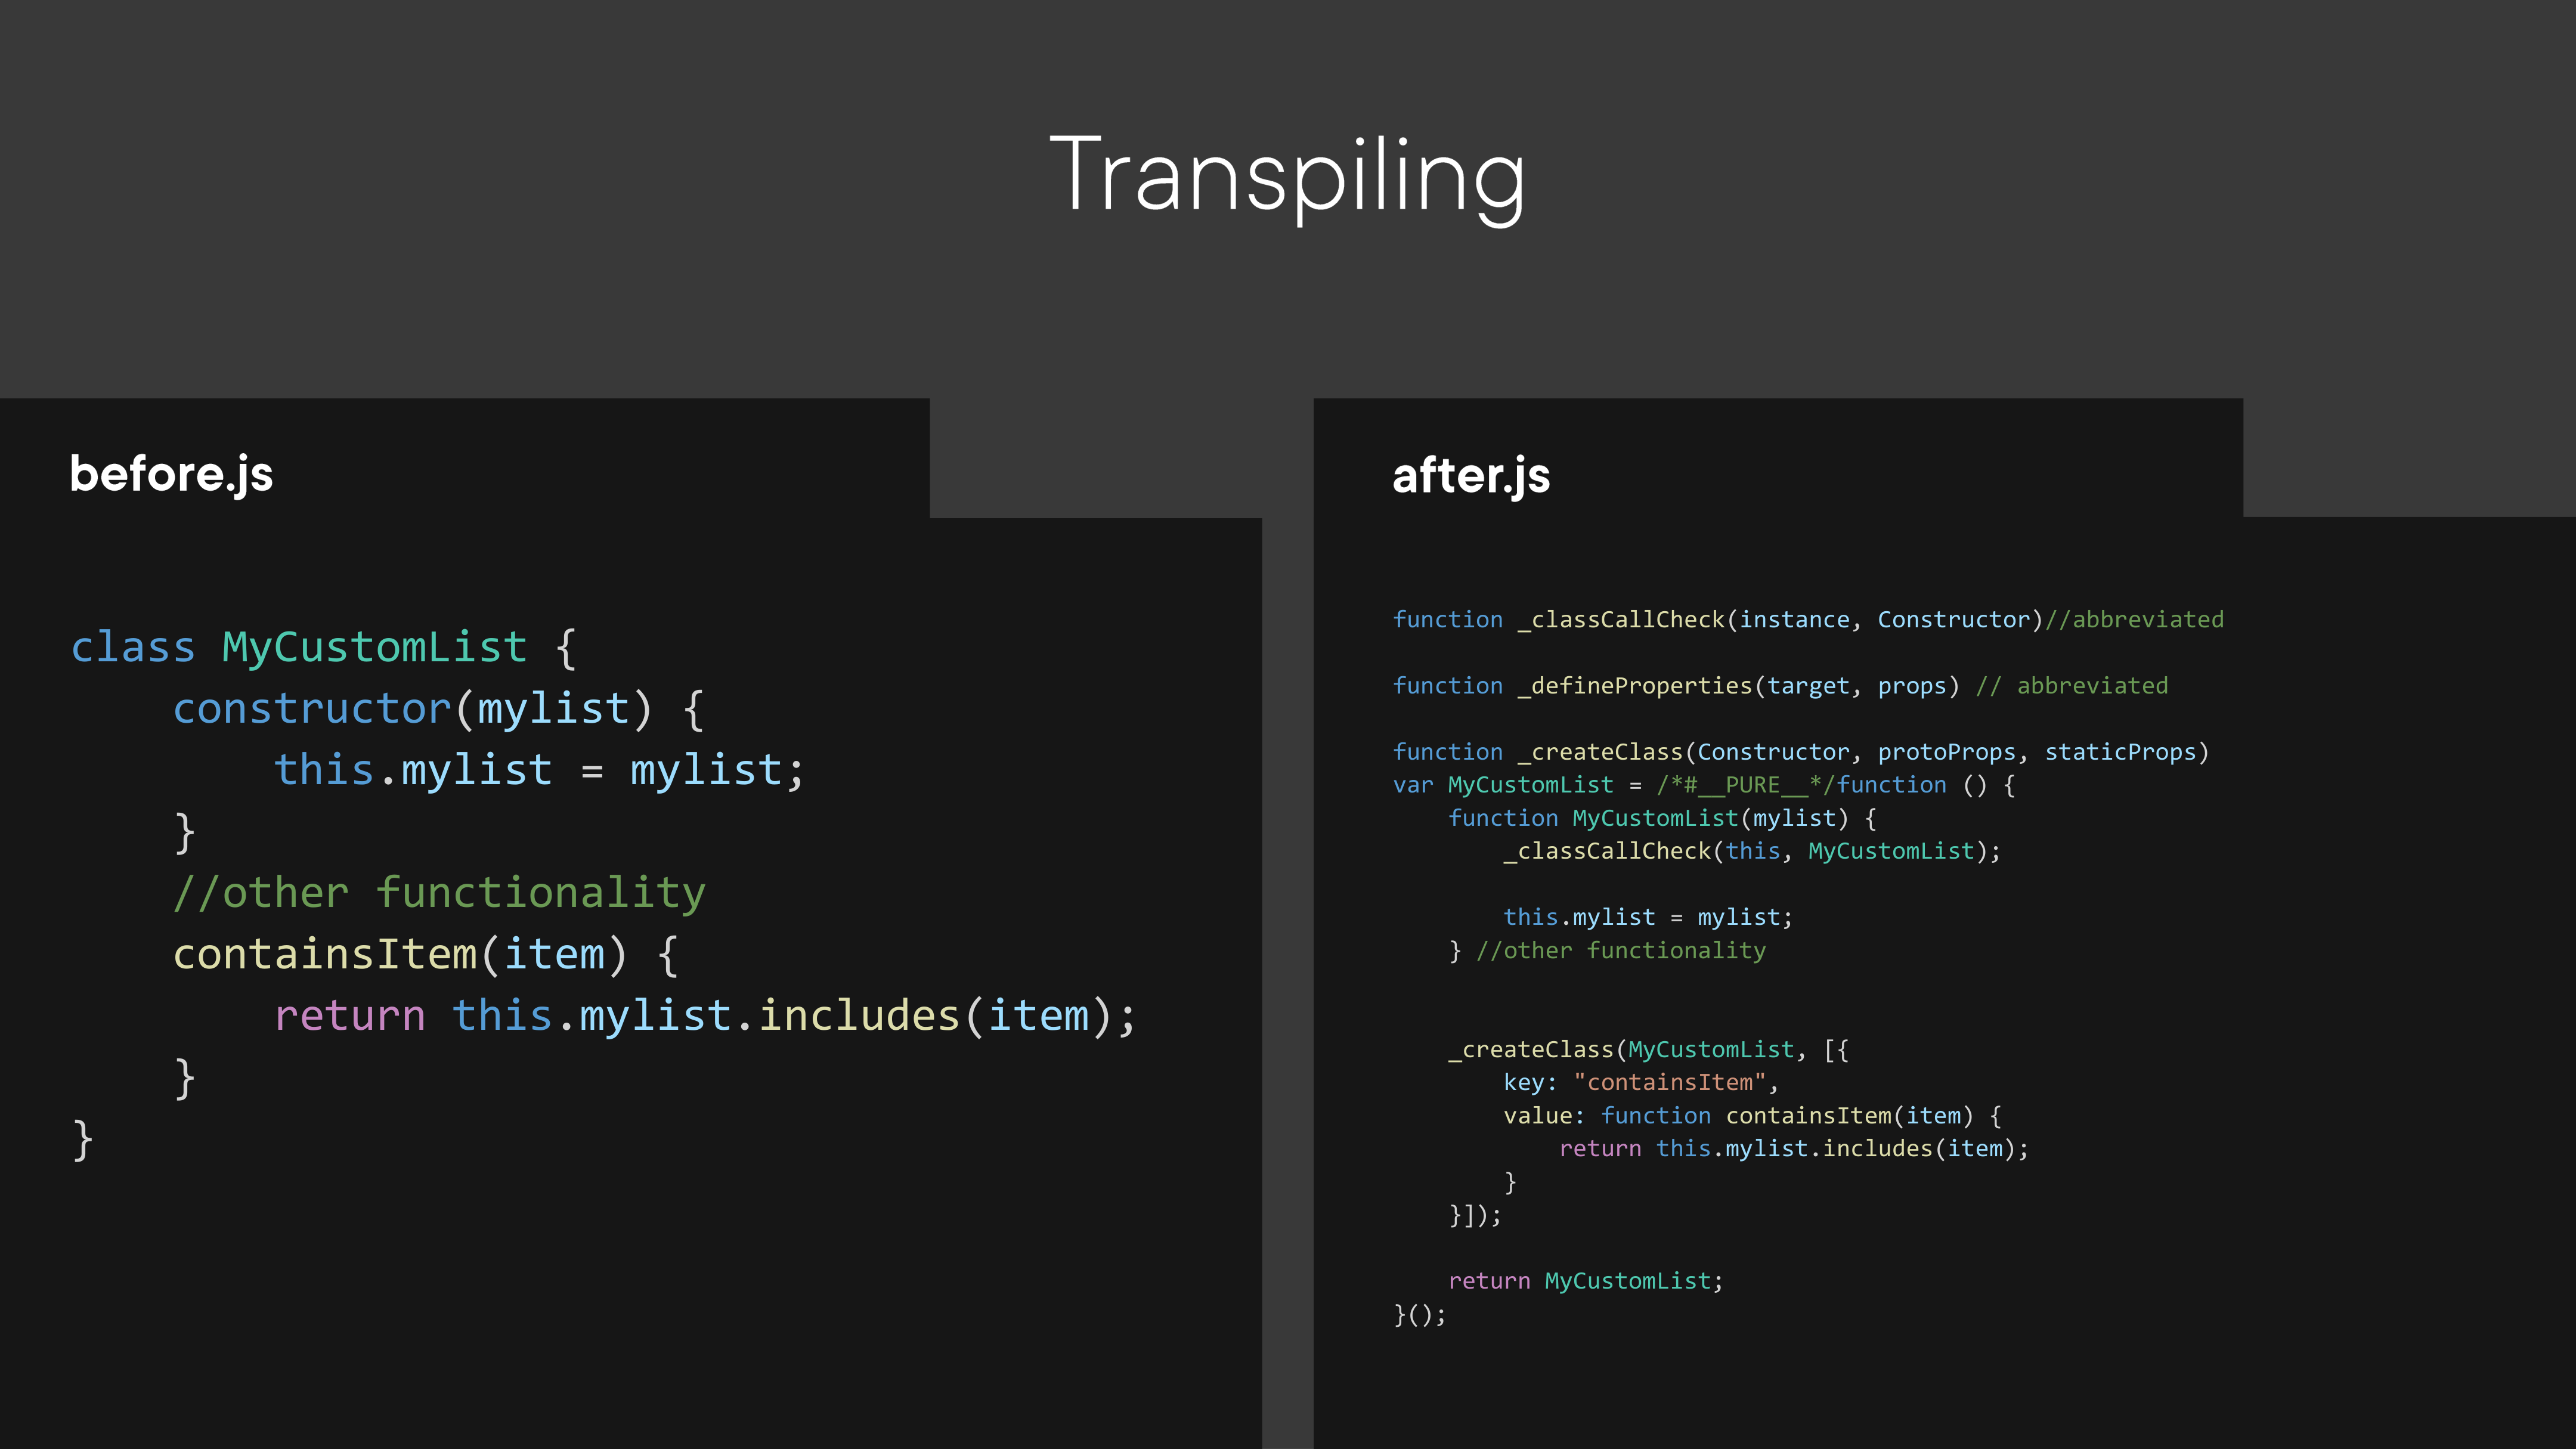

In [6]:
render_diagram(Path("assets/04-transpiling-class-comparison.png"))

### Introducing core-js

**core-js** is the standard polyfilling library for JavaScript. It provides implementations of:

| Category | Methods |
|---|---|
| Array | `includes()`, `find()`, `findIndex()`, `flatMap()`, `sort()` |
| String | `padStart()`, `padEnd()`, `repeat()`, `trimStart()` |
| Object | `assign()`, `entries()`, `values()` |
| Math | `sign()`, `trunc()` |
| Async | `Promise` |

### Installing core-js

There are four approaches, each with different trade-offs:

#### 1. HTML Script Tag (CDN)

Fastest to set up — includes the full polyfill bundle from a CDN:

```html
<head>
  <script src="https://cdn.jsdelivr.net/npm/core-js@3.10.2/minified.min.js"></script>
</head>
```

Use this if you need to polyfill a broad set of features and are not using a build tool.

#### 2. npm Import (full bundle)

Install via npm and import the entire polyfill at the entry point:

```bash
npm install core-js
```

```javascript
import 'core-js';
```

#### 3. npm Import (specific features)

Import only the features you need — reduces bundle size:

```javascript
import 'core-js/library/fn/array/find';
import 'core-js/library/fn/string/pad-start';
```

#### 4. Polyfill Service

Use a hosted polyfill service that detects the browser and sends only the polyfills it needs:

```html
<head>
  <script src="https://polyfill.io/v3/polyfill.min.js?features=Array.prototype.find,String.prototype.padStart"></script>
</head>
```

This is the most bandwidth-efficient approach for production.

### Demo: Polyfilling with core-js and Webpack

A countries search application that uses `core-js/actual` to polyfill all modern built-ins, bundled with Webpack.

See [`02-polyfilling-demos/`](02-polyfilling-demos/) for the full project.

```javascript
// src/index.js
import 'core-js/actual';  // polyfill all stable core-js features

var countries = [];
window.onload = function () {
  document.getElementById('search-button').onclick = function () {
    var searchTerm = document.getElementById("search").value;
    displayCountries(searchTerm);
  };
  fetch('https://restcountries.com/v3.1/all')
    .then(response => response.json())
    .then(data => { countries = data; displayCountries(''); });
};

function displayCountries(searchTerm) {
  var countriesList = document.getElementById("countries");
  countriesList.innerHTML = "";
  let filtered = searchTerm
    ? countries.filter(z => z.name.common.includes(searchTerm))
    : countries;
  filtered.forEach(country => {
    var li = document.createElement("li");
    li.classList = 'list-group-item';
    li.appendChild(document.createTextNode(country.name.common));
    countriesList.appendChild(li);
  });
}
```

Run the demo:
```bash
cd 02-polyfilling-demos/03_05
npm install
npm start   # webpack-dev-server at localhost:8080
```

<a id="module-03"></a>
## Module 03: TypeScript Transpiling

_Covers what TypeScript is, its benefits over plain JavaScript, how to write TypeScript code, and how to transpile it to JavaScript using the TypeScript compiler and Webpack._

### What is TypeScript?

TypeScript is a **statically-typed superset of JavaScript** developed by Microsoft. All valid JavaScript is also valid TypeScript, but TypeScript adds:

- **Static type annotations** — catch type errors at compile time, not runtime
- **Interfaces** — define the shape of objects
- **Generics** — type-safe reusable components
- **Strict null checks** — eliminates a whole class of `null`/`undefined` bugs

TypeScript files use the `.ts` extension and are **transpiled** to plain JavaScript before running in a browser or Node.js.

### Working with TypeScript

TypeScript adds type annotations alongside regular JavaScript:

```typescript
// Type annotations on variables and parameters
var countries: Countries[] = [];

function displayCountries(searchTerm: string) {
  const countriesList = document.getElementById("countries");
  if (countriesList) {
    // null check required by TypeScript strict mode
  }
}

// Interface defines the shape of an object
interface Countries {
  name: { common: string }
}
```

**Key TypeScript patterns:**
- `variable: Type` — annotate variable types
- `(param: Type)` — annotate function parameters
- `interface` — describe the shape of an object
- `as HTMLInputElement` — type assertion for DOM elements

### Configuring TypeScript (`tsconfig.json`)

The TypeScript compiler is configured via `tsconfig.json`:

```json
{
  "compilerOptions": {
    "target": "es2016",       // emit ES2016 JavaScript
    "module": "commonjs",     // use CommonJS modules
    "strict": true,           // enable all strict type-checking
    "esModuleInterop": true,  // CommonJS/ESM interop helpers
    "forceConsistentCasingInFileNames": true,
    "skipLibCheck": true
  }
}
```

The `target` option controls what version of JavaScript the TypeScript compiler outputs — `es2016` produces modern but broadly-supported JavaScript.

### Transpiling TypeScript with Webpack

For browser bundling, `ts-loader` integrates the TypeScript compiler into a Webpack build:

```bash
npm install --save-dev typescript ts-loader webpack webpack-cli
```

**`webpack.config.js`:**
```javascript
const path = require('path');

module.exports = {
  entry: './src/index.ts',
  output: {
    path: path.resolve(__dirname, './dist'),
    filename: 'bundle.js'
  },
  module: {
    rules: [
      {
        test: /\.tsx?$/,
        use: 'ts-loader',
        exclude: /node_modules/
      }
    ]
  },
  resolve: {
    extensions: ['.tsx', '.ts', '.js']
  }
};
```

Webpack passes `.ts` files through `ts-loader` which runs `tsc`, then bundles the output JavaScript.

### TypeScript with core-js Polyfills

TypeScript transpilation handles _type erasure and syntax_, but not missing built-ins. Combine with core-js for full browser support:

```typescript
import 'core-js/actual';  // polyfill at the entry point

var countries: Countries[] = [];
// ... rest of TypeScript application
```

The `index.js` emitted by `tsc` is standard CommonJS JavaScript — polyfills added via `core-js` work exactly the same as in plain JS projects.

### Demo: TypeScript Transpiling

Two demos showing TypeScript with Webpack — one without polyfills and one with core-js.

See [`03-typescript-transpiling-demos/`](03-typescript-transpiling-demos/) for the full project.

**Demo 04_02** — TypeScript + Webpack (no polyfills, type annotations only):
```typescript
// src/index.ts
var countries: Countries[] = [];

interface Countries {
  name: { common: string }
}

function displayCountries(searchTerm: string) {
  const countriesList = document.getElementById("countries");
  if (countriesList) {
    let filtered = searchTerm
      ? countries.filter(z => z.name.common.includes(searchTerm))
      : countries;
    filtered.forEach(country => {
      var li = document.createElement("li");
      li.classList.add('list-group-item');
      li.appendChild(document.createTextNode(country.name.common));
      countriesList.appendChild(li);
    });
  }
}
```

**Demo 04_03** — TypeScript + Webpack + core-js polyfills (production-ready combination):
```typescript
import 'core-js/actual';
// ... same TypeScript code as 04_02
```

Run either demo:
```bash
cd 03-typescript-transpiling-demos/04_02
npm install
npm start   # webpack-dev-server at localhost:8080
```